# Kidney Failure Prediction — Interim Analysis

**Group 2** · Charles Darwin University · Faculty of Science and Technology
**Unit:** HIT401 · **Supervisor:** Dr Asif Karim

| Student | ID |
|---|---|
| Abu Lise | s375172 |
| Raianul Islam | s377227 |
| Sadit Khan | s379452 |
| Tonmoy Acharjee | s375239 |

---

This notebook reproduces every figure and table in Sections 4 and 5 of the interim report.

**Contents**

1. Setup and data loading
2. Data cleaning
3. Missing-value profile
4. Encoding and the train/test split
5. Imputation strategy comparison
6. Exploratory data analysis
7. Classical models (RF, SVM, DT, Gradient Boosting)
8. Deep learning models (LSTM, GRU)
9. Results and evaluation figures
10. Diagnostic experiments — is the ceiling effect real signal?

**Reproducibility.** A fixed seed of 42 is set for Python, NumPy and TensorFlow. All
imputers and scalers are fitted on the **training partition only** and then applied to
the test partition. The test set is used once, at the end.

## 1. Setup and data loading

Install requirements if needed:

```
pip install pandas numpy scikit-learn tensorflow-cpu matplotlib seaborn
```

If you are running in Google Colab, mount Drive and set `RAW` to the path of the CSV.

In [1]:
import os, json, warnings, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve)

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)
os.makedirs("figures", exist_ok=True); os.makedirs("results", exist_ok=True)
sns.set_style("whitegrid")

RAW = "../data/kidney_disease.csv"   # <-- path relative to notebooks/

In [2]:
df = pd.read_csv(RAW)
if "id" in df.columns:
    df = df.drop(columns=["id"])
n_raw, p_raw = df.shape
print("Raw shape:", df.shape)
df.head()

Raw shape: (400, 25)


,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,121.0,...,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,NaN,...,38,6000,NaN,no,no,no,good,no,no,ckd
2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,423.0,...,31,7500,NaN,no,yes,no,poor,no,yes,ckd
3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,117.0,...,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,106.0,...,35,7300,4.6,no,no,no,good,no,no,ckd


## 2. Data cleaning

Three defects were found in the raw file:

1. **Trailing tab/whitespace characters** corrupted several categorical values, *including the
   target label itself* — `"ckd\t"` parses as a third class distinct from `"ckd"`.
2. **Three numeric attributes stored as text** (`pcv`, `wc`, `rc`) because of embedded whitespace.
3. Category variants that need to resolve to exactly two levels each.

In [3]:
# 2a. strip whitespace/tabs from every object column
obj_cols = df.select_dtypes(include=["object", "string"]).columns
for col in obj_cols:
    df[col] = df[col].astype(str).str.strip().str.replace(r"\s+", "", regex=True)
    df[col] = df[col].replace({"nan": np.nan, "": np.nan, "?": np.nan})

# 2b. numeric attributes stored as text
for col in ["pcv", "wc", "rc"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

TARGET = "classification"
df[TARGET] = df[TARGET].map({"ckd": 1, "notckd": 0})

num_cols = ["age", "bp", "sg", "al", "su", "bgr", "bu", "sc", "sod", "pot",
            "hemo", "pcv", "wc", "rc"]
cat_cols = ["rbc", "pc", "pcc", "ba", "htn", "dm", "cad", "appet", "pe", "ane"]

print("Category levels after cleaning (each should have exactly 2):")
for col in cat_cols:
    print(f"  {col:6s}", sorted(df[col].dropna().unique().tolist()))

dups = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
print(f"\nDuplicate rows removed: {dups}; shape now {df.shape}")

Category levels after cleaning (each should have exactly 2):
  rbc    ['abnormal', 'normal']
  pc     ['abnormal', 'normal']
  pcc    ['notpresent', 'present']
  ba     ['notpresent', 'present']
  htn    ['no', 'yes']
  dm     ['no', 'yes']
  cad    ['no', 'yes']
  appet  ['good', 'poor']
  pe     ['no', 'yes']
  ane    ['no', 'yes']

Duplicate rows removed: 0; shape now (400, 25)


## 3. Missing-value profile

This produces **Table 4-1** in the report. Missingness is severe and highly uneven — complete-case
analysis would discard three-fifths of the data, so it is rejected.

In [4]:
miss = (df.isna().mean() * 100).round(2).sort_values(ascending=False)
miss_tab = miss[miss > 0].reset_index()
miss_tab.columns = ["Attribute", "Missing (%)"]
miss_tab.to_csv("results/missingness.csv", index=False)

complete_cases = df.dropna().shape[0]
print(f"Complete cases: {complete_cases}/{len(df)} ({complete_cases/len(df)*100:.1f}%)")
miss_tab.head(15)

Complete cases: 158/400 (39.5%)


,Attribute,Missing (%)
0,rbc,38.00
1,rc,32.75
2,wc,26.50
3,pot,22.00
4,sod,21.75
5,pcv,17.75
6,pc,16.25
7,hemo,13.00
8,su,12.25
9,sg,11.75


## 4. Encoding and the train/test split

In [5]:
enc = df.copy()
bin_map = {"normal": 0, "abnormal": 1, "notpresent": 0, "present": 1,
           "no": 0, "yes": 1, "good": 0, "poor": 1}
for col in cat_cols:
    enc[col] = enc[col].map(bin_map)

X = enc.drop(columns=[TARGET])
y = enc[TARGET]
print("Class balance:", y.value_counts().to_dict())

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)
print(f"Train {X_tr.shape}, Test {X_te.shape}")

Class balance: {1: 250, 0: 150}
Train (320, 24), Test (80, 24)


### The leakage-control step

`build_pipeline` fits the imputer **and** the scaler on the training partition only, then applies
them to the test partition. Fitting either on the full dataset transfers information from the test
set into training, and is a plausible contributor to the inflated accuracies reported in the
literature (Kapoor and Narayanan, 2023).

In [6]:
def build_pipeline(kind):
    """Fit imputer + scaler on TRAIN only, then apply to both partitions."""
    Xtr, Xte = X_tr.copy(), X_te.copy()
    if kind == "simple":
        num_imp = SimpleImputer(strategy="median")
        cat_imp = SimpleImputer(strategy="most_frequent")
        Xtr[num_cols] = num_imp.fit_transform(Xtr[num_cols])
        Xte[num_cols] = num_imp.transform(Xte[num_cols])
        Xtr[cat_cols] = cat_imp.fit_transform(Xtr[cat_cols])
        Xte[cat_cols] = cat_imp.transform(Xte[cat_cols])
    else:  # knn
        imp = KNNImputer(n_neighbors=5)
        cols = list(Xtr.columns)
        sc0 = StandardScaler().fit(Xtr[num_cols])
        Xtr[num_cols] = sc0.transform(Xtr[num_cols])
        Xte[num_cols] = sc0.transform(Xte[num_cols])
        Xtr = pd.DataFrame(imp.fit_transform(Xtr), columns=cols, index=X_tr.index)
        Xte = pd.DataFrame(imp.transform(Xte), columns=cols, index=X_te.index)
        Xtr[cat_cols] = Xtr[cat_cols].round().clip(0, 1)
        Xte[cat_cols] = Xte[cat_cols].round().clip(0, 1)
        Xtr[num_cols] = sc0.inverse_transform(Xtr[num_cols])
        Xte[num_cols] = sc0.inverse_transform(Xte[num_cols])
    sc = StandardScaler().fit(Xtr)
    return (pd.DataFrame(sc.transform(Xtr), columns=Xtr.columns, index=Xtr.index),
            pd.DataFrame(sc.transform(Xte), columns=Xte.columns, index=Xte.index),
            Xtr, Xte)

## 5. Imputation strategy comparison

Two strategies are **compared** rather than one being assumed. This produces **Table 4-2**.
Evaluation is by five-fold cross-validated F1 inside the training partition only.

In [7]:
imp_rows = []
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
store = {}

for kind in ["simple", "knn"]:
    Xtr_s, Xte_s, Xtr_raw, Xte_raw = build_pipeline(kind)
    store[kind] = (Xtr_s, Xte_s, Xtr_raw, Xte_raw)
    for name, mdl in [("Random Forest", RandomForestClassifier(n_estimators=300, random_state=SEED)),
                      ("SVM (RBF)", SVC(probability=True, random_state=SEED))]:
        sc_ = cross_val_score(mdl, Xtr_s, y_tr, cv=cv, scoring="f1")
        imp_rows.append({"Imputation": "Median/Mode" if kind == "simple" else "KNN (k=5)",
                         "Model": name,
                         "CV F1 mean": round(sc_.mean(), 4),
                         "CV F1 SD": round(sc_.std(), 4)})

imp_df = pd.DataFrame(imp_rows)
imp_df.to_csv("results/imputation_comparison.csv", index=False)
imp_df

,Imputation,Model,CV F1 mean,CV F1 SD
0,Median/Mode,Random Forest,0.9951,0.0060
1,Median/Mode,SVM (RBF),0.9975,0.0051
2,KNN (k=5),Random Forest,0.9950,0.0061
3,KNN (k=5),SVM (RBF),0.9873,0.0081


In [8]:
best_kind = "knn" if imp_df[imp_df.Imputation.str.startswith("KNN")]["CV F1 mean"].mean() >= \
                     imp_df[imp_df.Imputation.str.startswith("Median")]["CV F1 mean"].mean() else "simple"
print("Selected imputation:", best_kind)
Xtr_s, Xte_s, Xtr_raw, Xte_raw = store[best_kind]

Selected imputation: simple


## 6. Exploratory data analysis

Produces **Fig. 4-1**, **Fig. 4-2** and **Fig. 4-3**.

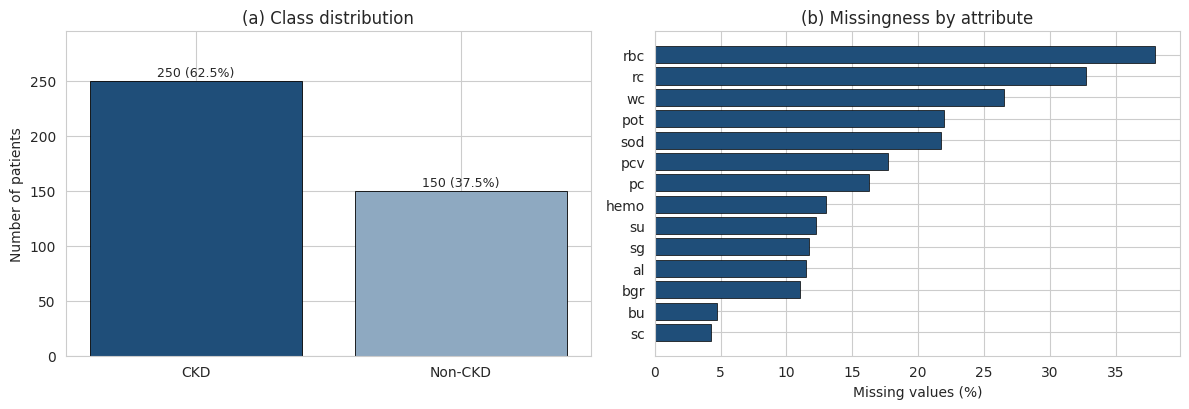

In [9]:
# Fig. 4-1 — class balance and missingness
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
cnt = y.map({1: "CKD", 0: "Non-CKD"}).value_counts()
ax[0].bar(cnt.index, cnt.values, color=["#1f4e79", "#8ea9c1"], edgecolor="black", linewidth=.6)
for i, v in enumerate(cnt.values):
    ax[0].text(i, v + 4, f"{v} ({v/len(y)*100:.1f}%)", ha="center", fontsize=9)
ax[0].set_ylabel("Number of patients"); ax[0].set_title("(a) Class distribution")
ax[0].set_ylim(0, max(cnt.values) * 1.18)

top_miss = miss[miss > 0].head(14)[::-1]
ax[1].barh(top_miss.index, top_miss.values, color="#1f4e79", edgecolor="black", linewidth=.5)
ax[1].set_xlabel("Missing values (%)"); ax[1].set_title("(b) Missingness by attribute")
plt.tight_layout(); plt.savefig("figures/fig4_1_class_missing.png", dpi=200); plt.show()

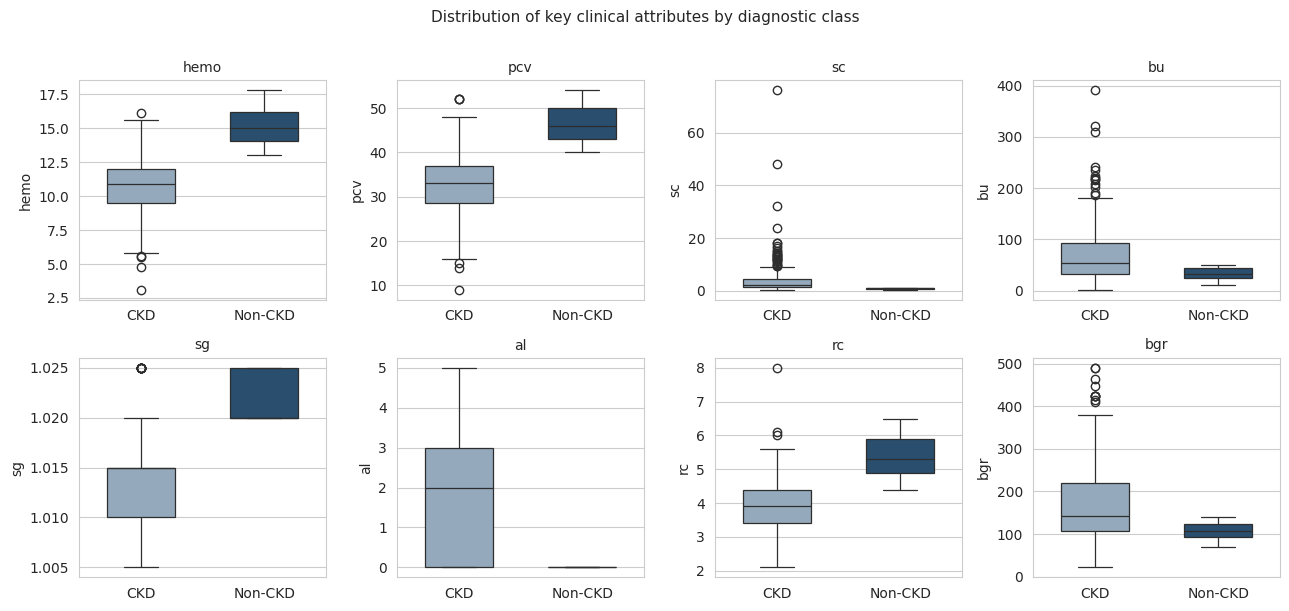

In [10]:
# Fig. 4-2 — key clinical attributes by class
key = ["hemo", "pcv", "sc", "bu", "sg", "al", "rc", "bgr"]
fig, axes = plt.subplots(2, 4, figsize=(13, 6))
for a, col in zip(axes.ravel(), key):
    d = df[[col, TARGET]].dropna()
    sns.boxplot(x=d[TARGET].map({1: "CKD", 0: "Non-CKD"}), y=d[col], ax=a,
                palette=["#8ea9c1", "#1f4e79"], width=.55, linewidth=.9)
    a.set_xlabel(""); a.set_title(col, fontsize=10)
plt.suptitle("Distribution of key clinical attributes by diagnostic class", y=1.01, fontsize=11)
plt.tight_layout(); plt.savefig("figures/fig4_2_boxplots.png", dpi=200, bbox_inches="tight"); plt.show()

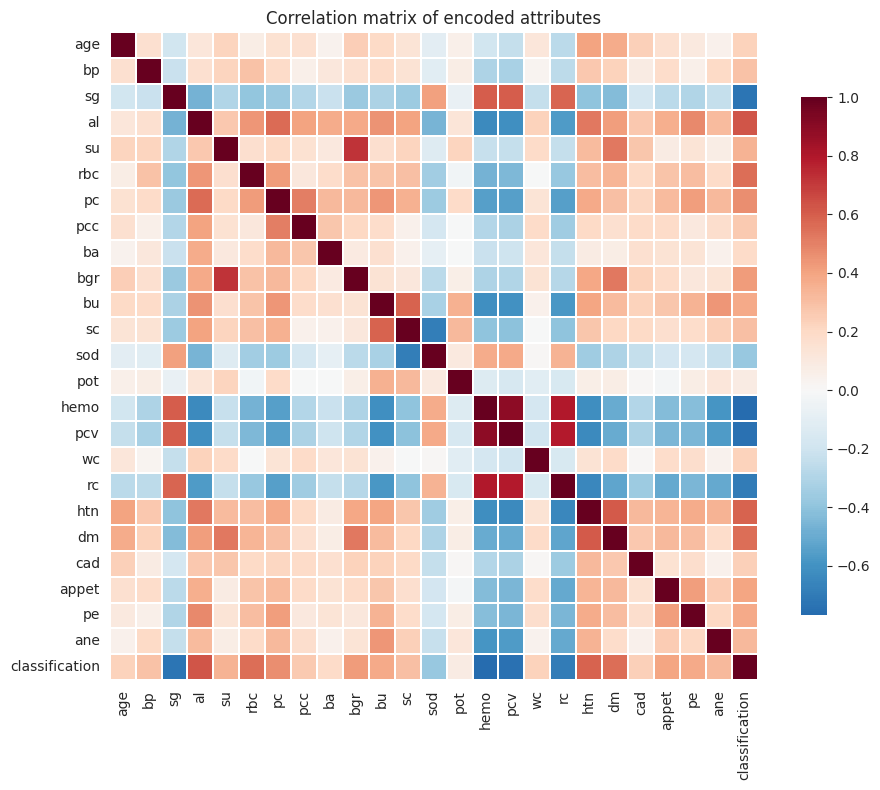

hemo   -0.769
pcv    -0.741
sg     -0.732
rc     -0.699
al      0.627
htn     0.589
dm      0.557
rbc     0.555
pc      0.462
bgr     0.420
Name: classification, dtype: float64

In [11]:
# Fig. 4-3 — correlation matrix
plt.figure(figsize=(10, 8))
corr = enc.corr(numeric_only=True)
sns.heatmap(corr, cmap="RdBu_r", center=0, square=True, linewidths=.3,
            cbar_kws={"shrink": .8}, annot=False)
plt.title("Correlation matrix of encoded attributes")
plt.tight_layout(); plt.savefig("figures/fig4_3_corr.png", dpi=200); plt.show()

corr_target = corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
corr_target.round(3).to_csv("results/target_correlation.csv")
corr_target.head(10).round(3)

## 7. Classical models

Four learners tuned by grid search, with five-fold cross-validation **inside the training
partition**. Hyper-parameters are selected on F1, then the best estimator is evaluated once on the
held-out test set.

In [12]:
grids = {
    "Random Forest": (RandomForestClassifier(random_state=SEED),
                      {"n_estimators": [100, 300], "max_depth": [None, 6, 10],
                       "min_samples_leaf": [1, 2]}),
    "SVM (RBF)": (SVC(probability=True, random_state=SEED),
                  {"C": [0.5, 1, 10], "gamma": ["scale", 0.05]}),
    "Decision Tree": (DecisionTreeClassifier(random_state=SEED),
                      {"max_depth": [3, 5, None], "min_samples_leaf": [1, 3, 5],
                       "criterion": ["gini", "entropy"]}),
    "Gradient Boosting": (GradientBoostingClassifier(random_state=SEED),
                          {"n_estimators": [100, 300], "learning_rate": [0.05, 0.1],
                           "max_depth": [2, 3]}),
}

results, probs, fitted = [], {}, {}
for name, (est, grid) in grids.items():
    gs = GridSearchCV(est, grid, cv=cv, scoring="f1", n_jobs=-1)
    gs.fit(Xtr_s, y_tr)
    best = gs.best_estimator_
    fitted[name] = best
    yp = best.predict(Xte_s)
    pr = best.predict_proba(Xte_s)[:, 1]
    probs[name] = pr
    cvf1 = cross_val_score(best, Xtr_s, y_tr, cv=cv, scoring="f1")
    results.append({
        "Model": name, "Type": "Classical",
        "CV F1 (mean)": round(cvf1.mean(), 4), "CV F1 (SD)": round(cvf1.std(), 4),
        "Accuracy": round(accuracy_score(y_te, yp), 4),
        "Precision": round(precision_score(y_te, yp), 4),
        "Recall": round(recall_score(y_te, yp), 4),
        "F1": round(f1_score(y_te, yp), 4),
        "ROC-AUC": round(roc_auc_score(y_te, pr), 4),
        "Best params": json.dumps(gs.best_params_)})
    print(f"{name:20s} acc={results[-1]['Accuracy']:.4f}  recall={results[-1]['Recall']:.4f}")

pd.DataFrame(results)[["Model", "Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]]

Random Forest        acc=1.0000  recall=1.0000


SVM (RBF)            acc=1.0000  recall=1.0000


Decision Tree        acc=0.9750  recall=0.9800


Gradient Boosting    acc=1.0000  recall=1.0000


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Random Forest,1.000,1.00,1.00,1.00,1.0000
1,SVM (RBF),1.000,1.00,1.00,1.00,1.0000
2,Decision Tree,0.975,0.98,0.98,0.98,0.9893
3,Gradient Boosting,1.000,1.00,1.00,1.00,1.0000


## 8. Deep learning models (LSTM, GRU)

**Note on the architectural mismatch.** This dataset has no temporal structure: each record is a
single static observation of one patient. Reshaping 24 attributes into a length-24 pseudo-sequence
gives the recurrent gates an ordering to model that is an artefact of column order and carries no
clinical meaning. The models are included for comparability with the specified project structure,
and the mismatch is discussed explicitly in Section 5 of the report.

In [13]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
tf.random.set_seed(SEED)

Xtr3 = Xtr_s.values.reshape((Xtr_s.shape[0], Xtr_s.shape[1], 1)).astype("float32")
Xte3 = Xte_s.values.reshape((Xte_s.shape[0], Xte_s.shape[1], 1)).astype("float32")

def make_rnn(cell):
    L = layers.LSTM if cell == "LSTM" else layers.GRU
    m = keras.Sequential([
        keras.Input(shape=(Xtr3.shape[1], 1)),
        L(64, return_sequences=True), layers.Dropout(0.3),
        L(32), layers.Dropout(0.3),
        layers.Dense(16, activation="relu"),
        layers.Dense(1, activation="sigmoid")])
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy",
              metrics=["accuracy"])
    return m

hist_store = {}
for cell in ["LSTM", "GRU"]:
    tf.keras.utils.set_random_seed(SEED)
    m = make_rnn(cell)
    es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=15,
                                       restore_best_weights=True)
    h = m.fit(Xtr3, y_tr.values, validation_split=0.2, epochs=150, batch_size=16,
              callbacks=[es], verbose=0)
    hist_store[cell] = h.history
    pr = m.predict(Xte3, verbose=0).ravel()
    yp = (pr >= 0.5).astype(int)
    probs[cell] = pr
    results.append({
        "Model": cell, "Type": "Deep Learning",
        "CV F1 (mean)": np.nan, "CV F1 (SD)": np.nan,
        "Accuracy": round(accuracy_score(y_te, yp), 4),
        "Precision": round(precision_score(y_te, yp), 4),
        "Recall": round(recall_score(y_te, yp), 4),
        "F1": round(f1_score(y_te, yp), 4),
        "ROC-AUC": round(roc_auc_score(y_te, pr), 4),
        "Best params": f"2 layers (64,32), dropout 0.3, Adam 1e-3, epochs run={len(h.history['loss'])}"})
    print(f"{cell:6s} acc={results[-1]['Accuracy']:.4f}  recall={results[-1]['Recall']:.4f}  "
          f"epochs={len(h.history['loss'])}")

I0000 00:00:1788541351.134064     514 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1788541365.795027     514 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1788541373.851516     514 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


LSTM   acc=0.9500  recall=0.9400  epochs=45


GRU    acc=0.9625  recall=0.9600  epochs=112


## 9. Results and evaluation figures

Produces **Table 5-1** and **Fig. 5-1** to **Fig. 5-4**, plus **Fig. 5-6**.

In [14]:
res = pd.DataFrame(results)
res.to_csv("results/model_results.csv", index=False)
res[["Model", "Type", "CV F1 (mean)", "Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]]

,Model,Type,CV F1 (mean),Accuracy,Precision,Recall,F1,ROC-AUC
0,Random Forest,Classical,0.9951,1.0000,1.0000,1.00,1.0000,1.0000
1,SVM (RBF),Classical,0.9975,1.0000,1.0000,1.00,1.0000,1.0000
2,Decision Tree,Classical,0.9780,0.9750,0.9800,0.98,0.9800,0.9893
3,Gradient Boosting,Classical,0.9926,1.0000,1.0000,1.00,1.0000,1.0000
4,LSTM,Deep Learning,NaN,0.9500,0.9792,0.94,0.9592,0.9840
5,GRU,Deep Learning,NaN,0.9625,0.9796,0.96,0.9697,0.9840


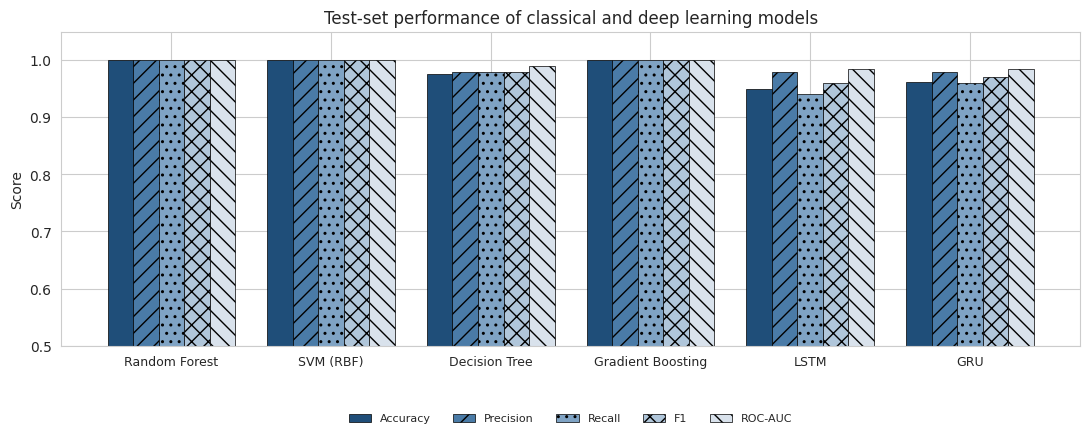

In [15]:
# Fig. 5-1 — metric comparison
metrics = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
x = np.arange(len(res)); w = 0.16
hatches = ["", "//", "..", "xx", "\\\\"]
greys = ["#1f4e79", "#4a7ba7", "#7fa3c4", "#b0c6da", "#d9e2ec"]
fig, ax = plt.subplots(figsize=(11, 4.6))
for i, mname in enumerate(metrics):
    ax.bar(x + (i - 2) * w, res[mname], w, label=mname, color=greys[i],
           edgecolor="black", linewidth=.5, hatch=hatches[i])
ax.set_xticks(x); ax.set_xticklabels(res["Model"], fontsize=9)
ax.set_ylim(0.5, 1.05); ax.set_ylabel("Score")
ax.set_title("Test-set performance of classical and deep learning models")
ax.legend(ncol=5, fontsize=8, loc="lower center", bbox_to_anchor=(0.5, -0.28), frameon=False)
plt.tight_layout(); plt.savefig("figures/fig5_1_metrics.png", dpi=200, bbox_inches="tight"); plt.show()

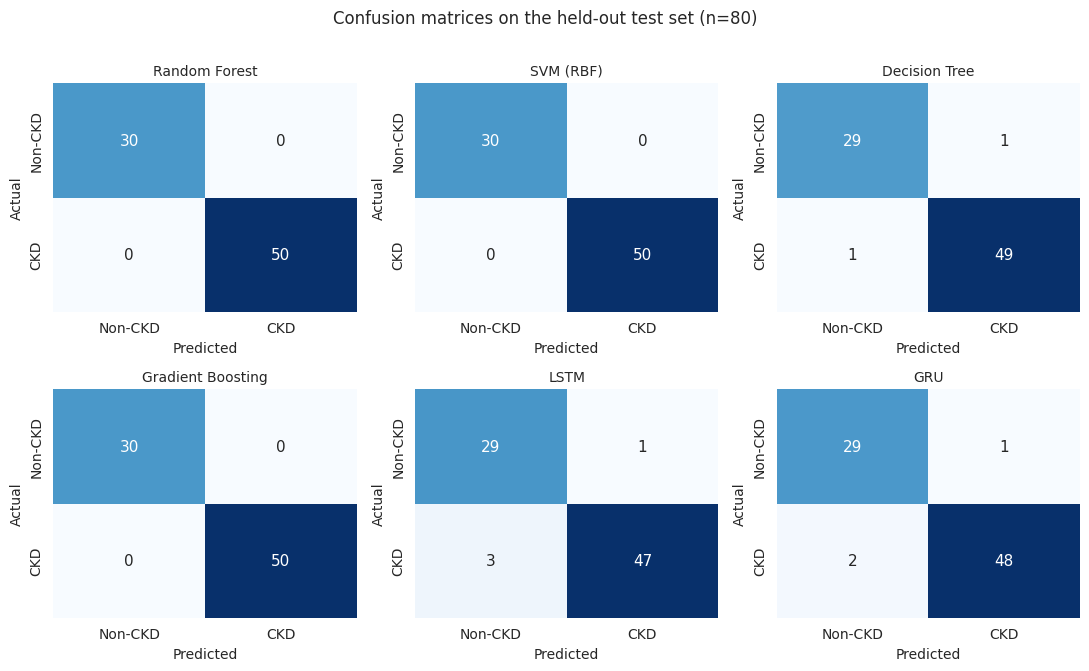

In [16]:
# Fig. 5-2 — confusion matrices
fig, axes = plt.subplots(2, 3, figsize=(11, 6.6))
for a, name in zip(axes.ravel(), res["Model"]):
    yp = (probs[name] >= 0.5).astype(int)
    cm = confusion_matrix(y_te, yp)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=a,
                xticklabels=["Non-CKD", "CKD"], yticklabels=["Non-CKD", "CKD"],
                annot_kws={"size": 11})
    a.set_title(name, fontsize=10); a.set_xlabel("Predicted"); a.set_ylabel("Actual")
plt.suptitle(f"Confusion matrices on the held-out test set (n={len(y_te)})", y=1.01)
plt.tight_layout(); plt.savefig("figures/fig5_2_confusion.png", dpi=200, bbox_inches="tight"); plt.show()

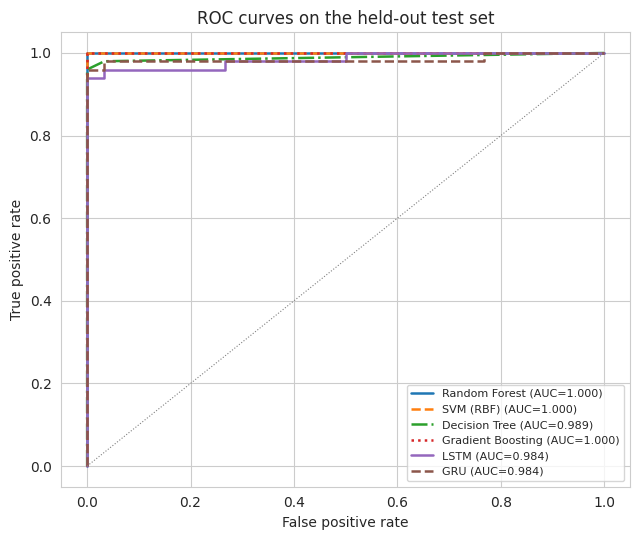

In [17]:
# Fig. 5-3 — ROC curves
plt.figure(figsize=(6.5, 5.5))
styles = ["-", "--", "-.", ":", "-", "--"]
for (name, pr), st in zip(probs.items(), styles):
    fpr, tpr, _ = roc_curve(y_te, pr)
    plt.plot(fpr, tpr, st, lw=1.8, label=f"{name} (AUC={roc_auc_score(y_te, pr):.3f})")
plt.plot([0, 1], [0, 1], color="grey", lw=.8, ls=":")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curves on the held-out test set"); plt.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig("figures/fig5_3_roc.png", dpi=200); plt.show()

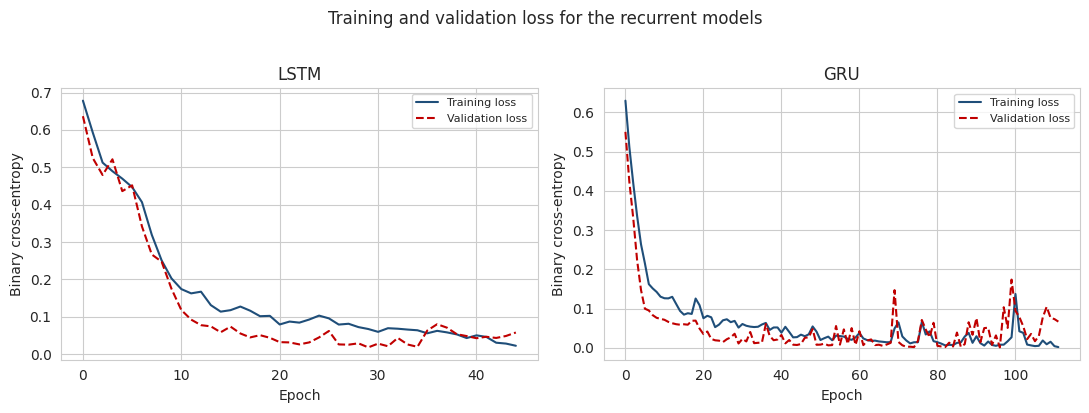

In [18]:
# Fig. 5-4 — training curves for the recurrent models
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for a, cell in zip(axes, ["LSTM", "GRU"]):
    h = hist_store[cell]
    a.plot(h["loss"], "-", color="#1f4e79", label="Training loss")
    a.plot(h["val_loss"], "--", color="#c00000", label="Validation loss")
    a.set_xlabel("Epoch"); a.set_ylabel("Binary cross-entropy")
    a.set_title(cell); a.legend(fontsize=8)
plt.suptitle("Training and validation loss for the recurrent models", y=1.02)
plt.tight_layout(); plt.savefig("figures/fig5_5_curves.png", dpi=200, bbox_inches="tight"); plt.show()

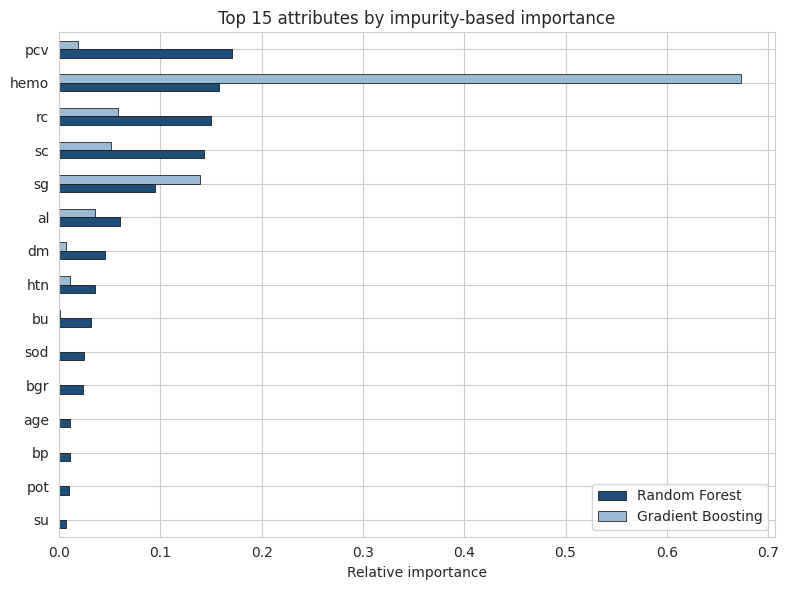

In [19]:
# Fig. 5-6 — feature importance
fi = pd.DataFrame({
    "Random Forest": fitted["Random Forest"].feature_importances_,
    "Gradient Boosting": fitted["Gradient Boosting"].feature_importances_},
    index=Xtr_s.columns).sort_values("Random Forest", ascending=True).tail(15)
fi.to_csv("results/feature_importance.csv")
ax = fi.plot.barh(figsize=(8, 6), color=["#1f4e79", "#9dbad4"], edgecolor="black", linewidth=.5)
ax.set_xlabel("Relative importance"); ax.set_title("Top 15 attributes by impurity-based importance")
plt.tight_layout(); plt.savefig("figures/fig5_4_importance.png", dpi=200); plt.show()

## 10. Diagnostic experiments — is the ceiling effect real signal?

Three models reach 100% accuracy. In clinical prediction that is a **warning, not a result**. The
experiments below test whether the performance reflects genuine clinical signal or properties of
the dataset itself. They produce **Table 5-2** and **Fig. 5-5**.

- **10a.** How much of the label can a *single attribute* explain?
- **10b.** Can the **pattern of missing values alone** — with every clinical measurement deleted —
  predict the diagnosis?
- **10c.** Is missingness associated with the diagnostic class?

In [20]:
raw = pd.read_csv(RAW)
if "id" in raw.columns:
    raw = raw.drop(columns=["id"])
for col in raw.select_dtypes(include=["object", "string"]).columns:
    raw[col] = raw[col].astype(str).str.strip().replace({"nan": np.nan, "": np.nan})
yr = raw["classification"].map({"ckd": 1, "notckd": 0})
mask = raw.drop(columns=["classification"]).isna().astype(int)

# 10c. class-conditional missingness
row_miss = raw.drop(columns=["classification"]).isna().mean(axis=1) * 100
diag = {
    "mean_row_missing_ckd_pct": round(row_miss[yr == 1].mean(), 2),
    "mean_row_missing_nonckd_pct": round(row_miss[yr == 0].mean(), 2),
    "complete_rows_ckd": int(((row_miss == 0) & (yr == 1)).sum()),
    "complete_rows_nonckd": int(((row_miss == 0) & (yr == 0)).sum()),
}

# 10b. missingness mask ONLY - no clinical values at all
acc_mask = cross_val_score(RandomForestClassifier(n_estimators=300, random_state=SEED),
                           mask, yr, cv=cv, scoring="accuracy")
diag["rf_missingness_mask_only_cv_acc"] = round(acc_mask.mean(), 4)
diag["rf_missingness_mask_only_cv_sd"] = round(acc_mask.std(), 4)

# 10a. single-attribute decision stumps (depth 1)
stumps = {}
for f in ["hemo", "sg", "al", "pcv", "rc", "sc"]:
    v = pd.to_numeric(raw[f], errors="coerce")
    ok = v.notna()
    sc_ = cross_val_score(DecisionTreeClassifier(max_depth=1, random_state=SEED),
                          v[ok].values.reshape(-1, 1), yr[ok], cv=5, scoring="accuracy")
    stumps[f] = round(sc_.mean(), 4)
diag["depth1_stump_cv_acc"] = stumps

# complete-case sensitivity check
cc = enc.dropna()
Xc, yc = cc.drop(columns=[TARGET]), cc[TARGET]
sc_cc = StandardScaler().fit_transform(Xc)
acc_cc = cross_val_score(RandomForestClassifier(n_estimators=300, random_state=SEED),
                         sc_cc, yc, cv=cv, scoring="accuracy")
diag["complete_case_n"] = int(len(cc))
diag["complete_case_rf_cv_acc"] = round(acc_cc.mean(), 4)

json.dump(diag, open("results/diagnostics.json", "w"), indent=2)
print(json.dumps(diag, indent=2))

{
  "mean_row_missing_ckd_pct": 15.08,
  "mean_row_missing_nonckd_pct": 2.89,
  "complete_rows_ckd": 43,
  "complete_rows_nonckd": 115,
  "rf_missingness_mask_only_cv_acc": 0.82,
  "rf_missingness_mask_only_cv_sd": 0.0376,
  "depth1_stump_cv_acc": {
    "hemo": 0.9224,
    "sg": 0.8808,
    "al": 0.8474,
    "pcv": 0.8935,
    "rc": 0.8809,
    "sc": 0.8826
  },
  "complete_case_n": 158,
  "complete_case_rf_cv_acc": 1.0
}


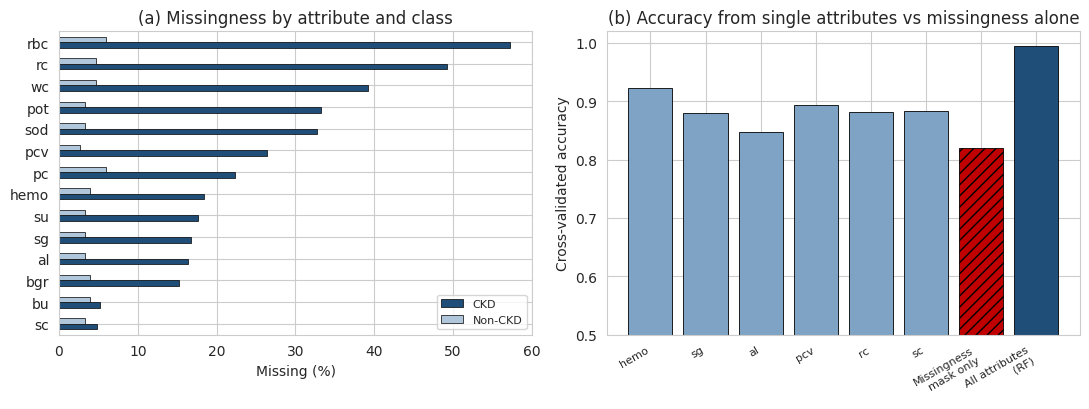

In [21]:
# Fig. 5-5 — diagnostic figure
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))

cm_ = pd.DataFrame({
    "CKD": raw[yr == 1].isna().mean() * 100,
    "Non-CKD": raw[yr == 0].isna().mean() * 100}).drop(index="classification")
cm_ = cm_[cm_.sum(axis=1) > 0].sort_values("CKD", ascending=True).tail(14)
cm_.plot.barh(ax=ax[0], color=["#1f4e79", "#b0c6da"], edgecolor="black", linewidth=.5)
ax[0].set_xlabel("Missing (%)"); ax[0].set_title("(a) Missingness by attribute and class")
ax[0].legend(fontsize=8)

names = list(stumps.keys()) + ["Missingness\nmask only", "All attributes\n(RF)"]
vals = list(stumps.values()) + [acc_mask.mean(), 0.995]
bars = ax[1].bar(range(len(vals)), vals,
                 color=["#7fa3c4"] * len(stumps) + ["#c00000", "#1f4e79"],
                 edgecolor="black", linewidth=.6)
bars[len(stumps)].set_hatch("///")
ax[1].set_xticks(range(len(vals))); ax[1].set_xticklabels(names, fontsize=8, rotation=30, ha="right")
ax[1].set_ylim(0.5, 1.02); ax[1].set_ylabel("Cross-validated accuracy")
ax[1].set_title("(b) Accuracy from single attributes vs missingness alone")

plt.tight_layout(); plt.savefig("figures/fig5_6_diagnostics.png", dpi=200, bbox_inches="tight"); plt.show()

### Interpretation

Three findings, all reported in Section 5 of the interim report:

1. A **depth-1 decision stump on haemoglobin alone** — one threshold, no interactions — reaches
   **92.2%** cross-validated accuracy. Five other attributes individually exceed 84%. The dataset is
   close to linearly separable on single clinical measurements.
2. A Random Forest given **only the missingness mask**, with every clinical measurement removed,
   still reaches **82.0%** accuracy.
3. CKD records average **15.1%** missing cells against **2.9%** for non-CKD records. `rbc` is absent
   in 57.2% of CKD records but only 6.0% of non-CKD records.

This is label leakage of the kind catalogued by Kapoor and Narayanan (2023). In Rubin's (1976)
terms the data are not missing at random but missing in a way that depends on the outcome. Any
imputation propagates that class-dependent signal into the completed data, so part of what every
model on this benchmark learns — including the models above — is an administrative artefact of how
the data was collected rather than the physiology of kidney disease.

### Next steps (Section 7 of the report)

- Retrain on the 158-record complete-case subset and, separately, with explicit missingness-indicator
  features, to separate clinical signal from the missingness pattern.
- Seek an independent CKD dataset for external validation.
- Apply SHAP to the ensemble models and repeat on the complete-case subset.
- Add tabular-specific architectures (TabNet, 1D-CNN) alongside LSTM and GRU.

### References for methods used here

- Kapoor, S. and Narayanan, A. (2023) 'Leakage and the reproducibility crisis in machine-learning-based science', *Patterns*, 4(9), 100804.
- Rubin, D.B. (1976) 'Inference and missing data', *Biometrika*, 63(3), pp. 581–592.
- Pedregosa, F. et al. (2011) 'Scikit-learn: machine learning in Python', *JMLR*, 12, pp. 2825–2830.
- Rubini, L.J., Soundarapandian, P. and Eswaran, P. (2015) *Chronic kidney disease dataset*. UCI Machine Learning Repository.